# Question 8 — Classifying Spam with Naive Bayes
steps:
1. Load and preprocess the training/test data.
2. Compute prior probabilities.
3. Estimate conditional probabilities using the m-estimate method.
4. Classify test emails and compute accuracy.
5. Study the effect of different m values.

We model each word as a feature and assume conditional independence given the class (spam or ham).

## 1. Load Dataset

Each line in the dataset contains:

`email_id label word1:count1 word2:count2 ...`

Example:
```
/inbox/123 ham hello:2 meeting:1
```

We parse this into a list of dictionaries containing the email ID, label, and a dictionary of word counts.

In [20]:
import os
import math
from collections import Counter
import matplotlib.pyplot as plt

def load_emails(file_path):
    emails = []
    with open(file_path, 'r') as f:
        for line in f:
            parts = line.strip().split()
            email_id = parts[0]
            label = parts[1]
            words = {}
            for word_count in parts[2:]:
                if ':' in word_count:
                    w, c = word_count.split(':')
                    words[w] = int(c)
                else:
                    words[word_count] = 1
            emails.append({'id': email_id, 'label': label, 'words': words})
    return emails

train_emails = load_emails('train')
test_emails = load_emails('test')
print(f"Loaded {len(train_emails)} training and {len(test_emails)} test emails.")

Loaded 9000 training and 1000 test emails.


## 2. Compute Prior Probabilities

We estimate the priors using Maximum Likelihood Estimation (MLE):

$$ P(\text{spam}) = \frac{N_{spam}}{N_{total}}, \quad P(\text{ham}) = \frac{N_{ham}}{N_{total}} $$

In [21]:
num_spam = sum(1 for e in train_emails if e['label'] == 'spam')
num_ham = sum(1 for e in train_emails if e['label'] == 'ham')
total_emails = len(train_emails)

P_spam = num_spam / total_emails
P_ham = num_ham / total_emails

print(f"P(spam) = {P_spam:.4f}, P(ham) = {P_ham:.4f}")

P(spam) = 0.5737, P(ham) = 0.4263


## 3. Vocabulary and Word Counts

We collect all unique words from the training set to form the vocabulary \( V \). Then we count how many times each word appears in spam and ham messages.

This will be used to estimate conditional probabilities.

In [22]:
vocab = set()
spam_counts = Counter()
ham_counts = Counter()
total_words_spam = 0
total_words_ham = 0

for e in train_emails:
    for word, count in e['words'].items():
        vocab.add(word)
        if e['label'] == 'spam':
            spam_counts[word] += count
            total_words_spam += count
        else:
            ham_counts[word] += count
            total_words_ham += count

V = len(vocab)
print(f"Vocabulary size: {V}")

Vocabulary size: 1330


## 4. Conditional Probabilities with *m*-Estimate

We compute the conditional probabilities using the *m-estimate* formula:

$$
P(w_i | c) = \frac{n_i + m p}{N + m}
$$

where:
- \($n_i$\): count of word \($w_i$\) in class \(c\)
- \(N\): total word count in class \(c\)
- \(p = $1/|V|$\): prior estimate of word probability
- \(m\): strength of the prior (smoothing parameter)

In [23]:
def compute_cond_probs(word_counts, total_words, vocab, m):
    p = 1 / len(vocab)
    cond_probs = {}
    for w in vocab:
        n_i = word_counts.get(w, 0)
        cond_probs[w] = (n_i + m * p) / (total_words + m)
    return cond_probs

cond_prob_spam = compute_cond_probs(spam_counts, total_words_spam, vocab, m=V)
cond_prob_ham = compute_cond_probs(ham_counts, total_words_ham, vocab, m=V)

top_spam = sorted(cond_prob_spam.items(), key=lambda x: x[1], reverse=True)[:5]
top_ham = sorted(cond_prob_ham.items(), key=lambda x: x[1], reverse=True)[:5]

print("Top 5 words for spam:", top_spam)
print("Top 5 words for ham:", top_ham)

Top 5 words for spam: [('3', 0.008104269493640095), ('nahou', 0.008104269493640095), ('technologies', 0.008104269493640095), ('content', 0.008104269493640095), ('with', 0.008104269493640095)]
Top 5 words for ham: [('3', 0.007225626688505455), ('1', 0.007225626688505455), ('4', 0.007225626688505455), ('2', 0.007225626688505455), ('enron', 0.007223744034339612)]


## 5. Classify Test Emails

We use log-probabilities to avoid numerical underflow:

$$
\log P(c|x) \propto \log P(c) + \sum_i x_i \log P(w_i|c)
$$

We classify an email as `spam` if $( \log P(\text{spam}|x) > \log P(\text{ham}|x) )$.

In [24]:
def classify_email(email_words, P_spam, P_ham, cond_prob_spam, cond_prob_ham):
    log_spam = math.log(P_spam)
    log_ham = math.log(P_ham)
    for w, count in email_words.items():
        if w in cond_prob_spam:
            log_spam += count * math.log(cond_prob_spam[w])
        if w in cond_prob_ham:
            log_ham += count * math.log(cond_prob_ham[w])
    return 'spam' if log_spam > log_ham else 'ham'

correct = 0
for e in test_emails:
    pred = classify_email(e['words'], P_spam, P_ham, cond_prob_spam, cond_prob_ham)
    if pred == e['label']:
        correct += 1

accuracy = correct / len(test_emails)
print(f"Test Accuracy (m=|V|): {accuracy:.4f}")

Test Accuracy (m=|V|): 0.9290


## 6. Vary *m* and Observe Effect

We vary the smoothing parameter *m* to see how accuracy changes.

We test:
$$
m = |V| \times [1, 10, 100, 1000, 10000]
$$

As *m* increases, the estimates move closer to the prior (uniform), and accuracy usually decreases slightly as model becomes less data-driven.

m =     1330, Accuracy = 0.9290
m =    13300, Accuracy = 0.9240
m =   133000, Accuracy = 0.9090
m =  1330000, Accuracy = 0.8500
m = 13300000, Accuracy = 0.8370


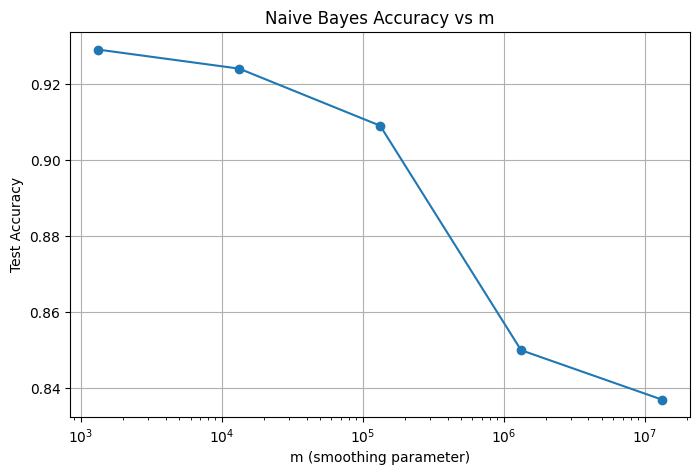

In [25]:
m_values = [V * 1, V * 10, V * 100, V * 1000, V * 10000]
accuracies = []

for m_val in m_values:
    cond_prob_spam_m = compute_cond_probs(spam_counts, total_words_spam, vocab, m=m_val)
    cond_prob_ham_m = compute_cond_probs(ham_counts, total_words_ham, vocab, m=m_val)

    correct_m = 0
    for e in test_emails:
        pred = classify_email(e['words'], P_spam, P_ham, cond_prob_spam_m, cond_prob_ham_m)
        if pred == e['label']:
            correct_m += 1
    acc = correct_m / len(test_emails)
    accuracies.append(acc)
    print(f"m = {m_val:>8}, Accuracy = {acc:.4f}")

# Plot
plt.figure(figsize=(8,5))
plt.plot(m_values, accuracies, marker='o')
plt.xscale('log')
plt.xlabel('m (smoothing parameter)')
plt.ylabel('Test Accuracy')
plt.title('Naive Bayes Accuracy vs m')
plt.grid(True)
plt.show()

## 7. Conclusion

- When m is small → the model relies heavily on observed word counts, risk of overfitting.
- When m is large → conditional probabilities approach the prior, reducing overfitting but possibly underfitting.
- The best accuracy usually occurs for moderate m values.